# Compare gold forecasting models
Run any model notebook first. This notebook reads saved predictions and never retrains models.
Models are compared on the intersection of observed targets and common forecast origins.
The persistence baseline predicts the gold price observed at the origin.

**SHORT WORKFLOW TEST ONLY:** one outer fold, one external-feature candidate; two maximum neural epochs / ten XGBoost trees. Not a forecasting-quality experiment.

In [1]:
from pathlib import Path
import os
# Limit CPU threads before importing optional numerical/model libraries.
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from model_lib.preprocessing import ROOT, load_config
cfg = load_config()
pd.set_option('display.max_columns', 20)
print('Project:', ROOT)
print('Target:', cfg['target_name'], '| horizons:', cfg['horizons'])

Project: /workspace/scratch/5a766a33a2c3/gold_forecasting
Target: Kitco Price (USD) | horizons: [1, 5, 20]


## 1. Load development results and check coverage

In [2]:
from model_lib.model_training import compare_results
import model_lib.model_training as model_utils
model_utils.ROOT = ROOT / 'validation'
predictions, results, coverage = compare_results('cv')
display(coverage)
print('Models currently available:', predictions.model.unique().tolist())
display(results)

Models currently available: ['gru', 'lstm', 'prophet', 'xgboost', 'persistence', 'trailing_drift']


,total_predictions,observed_targets,common_predictions
model,,,
gru,15,14,14
lstm,15,14,14
prophet,15,14,14
xgboost,15,14,14


,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,gru,cv_1,1,5,9.762504,11.746109,0.496073,1.014363,9.58,-0.019051
1,gru,cv_1,5,5,24.475903,28.747821,1.259625,2.543144,19.62,-0.247498
2,gru,cv_1,20,4,30.712861,36.492434,1.590617,3.191189,22.65,-0.355976
3,lstm,cv_1,1,5,11.972834,16.417816,0.605974,1.244025,9.58,-0.249774
4,lstm,cv_1,5,5,23.189920,27.155233,1.192115,2.409526,19.62,-0.181953
5,lstm,cv_1,20,4,28.836934,42.463195,1.501281,2.996273,22.65,-0.273154
6,persistence,cv_1,1,5,9.580000,12.063747,0.487317,0.995400,9.58,0.000000
7,persistence,cv_1,5,5,19.620000,25.841014,1.010948,2.038597,19.62,0.000000
8,persistence,cv_1,20,4,22.650000,29.598902,1.176421,2.353426,22.65,0.000000
9,prophet,cv_1,1,5,36.182382,54.399316,1.827663,3.759494,9.58,-2.776867


## 2. Compare pooled errors and fold stability

horizon,1,5,20
model,,,
gru,9.762504,24.475903,30.712861
lstm,11.972834,23.189920,28.836934
persistence,9.580000,19.620000,22.650000
prophet,36.182382,35.345982,36.253074
trailing_drift,9.335159,21.806111,22.714286
xgboost,9.729515,19.387670,22.803633


mean  std        min        max
model          horizon                                      
gru            1         9.762504  NaN   9.762504   9.762504
               5        24.475903  NaN  24.475903  24.475903
               20       30.712861  NaN  30.712861  30.712861
lstm           1        11.972834  NaN  11.972834  11.972834
               5        23.189920  NaN  23.189920  23.189920
               20       28.836934  NaN  28.836934  28.836934
persistence    1         9.580000  NaN   9.580000   9.580000
               5        19.620000  NaN  19.620000  19.620000
               20       22.650000  NaN  22.650000  22.650000
prophet        1        36.182382  NaN  36.182382  36.182382
               5        35.345982  NaN  35.345982  35.345982
               20       36.253074  NaN  36.253074  36.253074
trailing_drift 1         9.335159  NaN   9.335159   9.335159
               5        21.806111  NaN  21.806111  21.806111
               20       22.714286  NaN  22.714286  22.714286
xgboost        1         9.729515  NaN   9.729515   9.729515
               5        19.387670  NaN  19.387670  19.387670
               20       22.803633  NaN  22.803633  22.803633

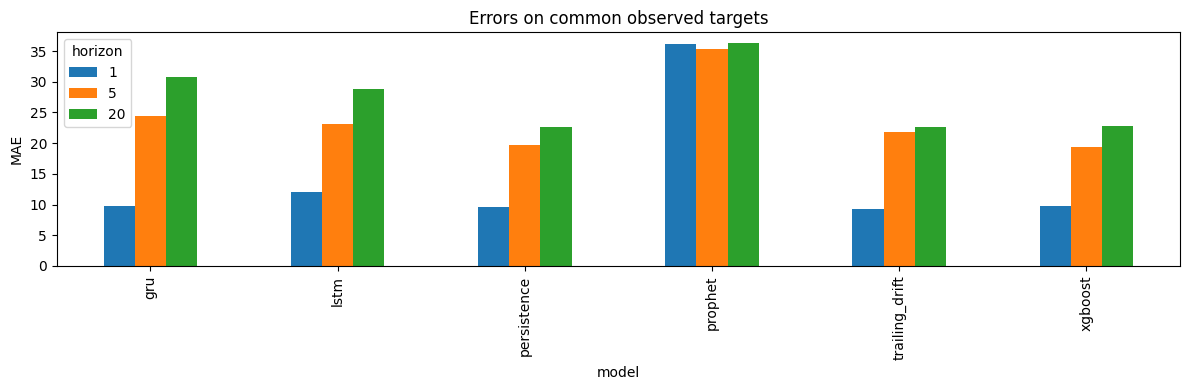

In [3]:
# Pooled MAE weights individual forecast errors equally within each horizon.
observed = predictions.dropna(subset=['actual', 'prediction']).copy()
observed['absolute_error'] = (observed.prediction - observed.actual).abs()
pooled = observed.groupby(['model', 'horizon']).absolute_error.mean().unstack('horizon')
display(pooled)
pooled.plot.bar(figsize=(12, 4), ylabel='MAE', title='Errors on common observed targets')
plt.tight_layout()
display(results.groupby(['model', 'horizon']).MAE.agg(['mean', 'std', 'min', 'max']))

## 3. Inspect residuals through time

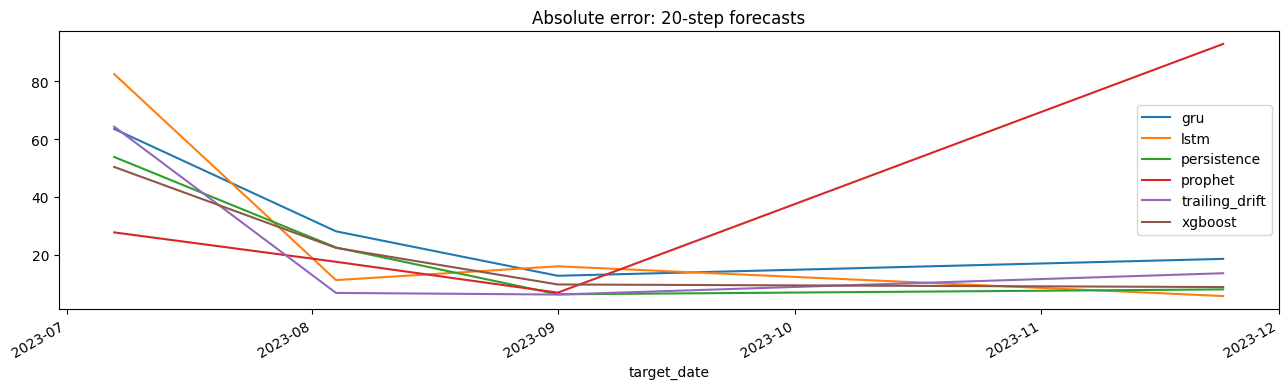

In [4]:
horizon = cfg['horizons'][-1]
fig, ax = plt.subplots(figsize=(13, 4))
for model, group in observed.loc[observed.horizon.eq(horizon)].groupby('model'):
    group.sort_values('target_date').plot(x='target_date', y='absolute_error', ax=ax, label=model)
ax.set_title(f'Absolute error: {horizon}-step forecasts')
plt.tight_layout()

## 4. Inspect external-feature selection
Inner scores show which feature group was selected without using the corresponding outer block.
Interpret importance as predictive association, not a causal explanation.

In [5]:
tables = []
for path in sorted((ROOT / 'artifacts').glob('*/inner_selection.csv')):
    table = pd.read_csv(path)
    table['model'] = path.parent.name
    tables.append(table)
if tables:
    selection = pd.concat(tables, ignore_index=True)
    selection['group'] = selection.params.map(lambda value: json.loads(value)['group'])
    display(selection.groupby(['model', 'group']).inner_MAE.agg(['mean', 'std', 'count']))

## 5. Review final holdout results if available
Keep these separate from development results. Do not retune using this table.
The current package does not claim uncertainty intervals or verified real-time release vintages.

In [6]:
holdout_files = list((ROOT / 'artifacts').glob('*/holdout_predictions.csv'))
if holdout_files:
    holdout_predictions, holdout_results, holdout_coverage = compare_results('holdout')
    display(holdout_coverage)
    display(holdout_results)
else:
    print('No holdout results yet.')

No holdout results yet.
